In [4]:
!pip -q install datasets transformers accelerate

In [2]:
import random, re, os, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

In [3]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("figures", exist_ok=True)
print("device:", device)

device: cuda


In [5]:
from datasets import load_dataset
ds = load_dataset("google-research-datasets/go_emotions", "simplified")
print(ds)
names = ds["train"].features["labels"].feature.names
NUM = len(names)
def to_df(split):
    d = ds[split].to_pandas()
    d = d[d["labels"].apply(len) == 1].copy()
    d["y"] = d["labels"].apply(lambda l: int(l[0]))
    return d[["text", "y"]].reset_index(drop=True)

train_df, val_df, test_df = to_df("train"), to_df("validation"), to_df("test")
print(len(train_df), len(val_df), len(test_df), "| classes:", NUM)
train_df.sample(5, random_state=0).assign(label=lambda d: d.y.map(lambda i: names[i]))[["text", "label"]]

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})
36308 4548 4590 | classes: 28


,text,label
2028,Yes every time,neutral
14914,"You are megalophobic, my friend. Welcome to th...",gratitude
33860,"What I said applies to all of /r/politics, not...",neutral
1479,stepped over that dude like he was [NAME]!,neutral
4301,Isn't it awesome. And then they get praised fo...,admiration


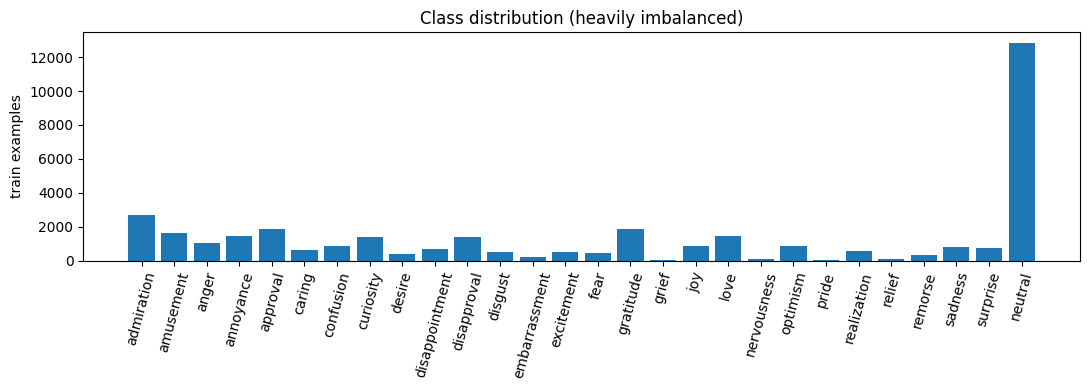

In [6]:
counts = train_df.y.value_counts().sort_index()
plt.figure(figsize=(11, 4))
plt.bar([names[i] for i in counts.index], counts.values)
plt.xticks(rotation=75); plt.ylabel("train examples"); plt.title("Class distribution (heavily imbalanced)")
plt.tight_layout(); plt.savefig("figures/class_distribution.png", dpi=150); plt.show()

In [7]:
cw = compute_class_weight("balanced", classes=np.arange(NUM), y=train_df.y.values)
cw_t = torch.tensor(cw, dtype=torch.float)

results = {}
def record(name, y_true, y_pred, extra=None):
    results[name] = dict(acc=accuracy_score(y_true, y_pred),
                         macro_f1=f1_score(y_true, y_pred, average="macro"),
                         weighted_f1=f1_score(y_true, y_pred, average="weighted"),
                         preds=np.array(y_pred))
    if extra: results[name].update(extra)
    r = results[name]
    print(f"{name}: acc={r['acc']:.3f}  macro-F1={r['macro_f1']:.3f}  weighted-F1={r['weighted_f1']:.3f}")

y_test = test_df.y.values

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(train_df.text); Xva = vec.transform(val_df.text); Xte = vec.transform(test_df.text)

best = None
for C_ in [1, 3, 10]:
    m = LogisticRegression(C=C_, max_iter=2000, class_weight="balanced").fit(Xtr, train_df.y)
    f = f1_score(val_df.y, m.predict(Xva), average="macro")
    print(f"C={C_}: val macro-F1={f:.3f}")
    if best is None or f > best[0]: best = (f, C_, m)
lr = best[2]
record("TF-IDF + LogReg", y_test, lr.predict(Xte))

C=1: val macro-F1=0.433
C=3: val macro-F1=0.440
C=10: val macro-F1=0.445
TF-IDF + LogReg: acc=0.506  macro-F1=0.421  weighted-F1=0.515


In [9]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding)
from datasets import Dataset

MODEL = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(MODEL)
def hf(df):
    d = Dataset.from_dict({"text": df.text.tolist(), "labels": df.y.tolist()})
    return d.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True, remove_columns=["text"])
hf_tr, hf_va, hf_te = hf(train_df), hf(val_df), hf(test_df)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        out = model(**inputs)
        loss = F.cross_entropy(out.logits, labels, weight=cw_t.to(out.logits.device))
        return (loss, out) if return_outputs else loss

def metrics(p):
    pr = p.predictions.argmax(1)
    return {"macro_f1": f1_score(p.label_ids, pr, average="macro"), "acc": accuracy_score(p.label_ids, pr)}

bert = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=NUM)
import math
steps_per_epoch = math.ceil(len(hf_tr) / 32)
total_steps = 4 * steps_per_epoch
warmup = int(0.1 * total_steps)          # same 10% warmup, expressed in steps

args = TrainingArguments(output_dir="out", num_train_epochs=4, per_device_train_batch_size=32,
                         per_device_eval_batch_size=128, learning_rate=5e-5, weight_decay=0.01,
                         warmup_steps=warmup, eval_strategy="epoch", save_strategy="epoch",
                         load_best_model_at_end=True, metric_for_best_model="macro_f1",
                         save_total_limit=1, fp16=torch.cuda.is_available(), seed=SEED, report_to="none")
trainer = WeightedTrainer(model=bert, args=args, train_dataset=hf_tr, eval_dataset=hf_va,
                          data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
trainer.train()
bert_logits = torch.tensor(trainer.predict(hf_te).predictions)
record("DistilBERT", y_test, bert_logits.argmax(1).numpy())

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/36308 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT: acc=0.492  macro-F1=0.478  weighted-F1=0.485


In [10]:
tokenize = lambda s: re.findall(r"[a-z']+|[!?.,]", s.lower())
cnt = Counter(t for s in train_df.text for t in tokenize(s))
vocab = {"<pad>": 0, "<unk>": 1}
for w, c in cnt.items():
    if c >= 2: vocab[w] = len(vocab)
print("vocab size:", len(vocab))

def encode(s, maxlen=50):
    ids = [vocab.get(t, 1) for t in tokenize(s)][:maxlen]
    return ids if ids else [1]

class DS(torch.utils.data.Dataset):
    def __init__(self, df): self.x = [encode(s) for s in df.text]; self.y = df.y.tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]

def collate(batch):
    xs, ys = zip(*batch)
    lens = torch.tensor([len(x) for x in xs])
    pad = torch.zeros(len(xs), lens.max(), dtype=torch.long)
    for i, x in enumerate(xs): pad[i, :len(x)] = torch.tensor(x)
    return pad, lens, torch.tensor(ys)

mk = lambda df, sh: torch.utils.data.DataLoader(DS(df), batch_size=64, shuffle=sh, collate_fn=collate)
tr_dl, va_dl, te_dl = mk(train_df, True), mk(val_df, False), mk(test_df, False)

class BiLSTM(nn.Module):
    def __init__(self, V, E=128, H=128, C=NUM, p=0.4):
        super().__init__()
        self.emb = nn.Embedding(V, E, padding_idx=0)
        self.lstm = nn.LSTM(E, H, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(p); self.fc = nn.Linear(2 * H, C)
    def forward(self, x, lens):
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        mask = (x != 0).unsqueeze(-1)
        pooled = out.masked_fill(~mask, -1e9).max(dim=1).values
        return self.fc(self.drop(pooled))

@torch.no_grad()
def predict_lstm(model, dl):
    model.eval(); P = []
    for x, l, y in dl: P.append(model(x.to(device), l).cpu())
    return torch.cat(P)

model = BiLSTM(len(vocab)).to(device)
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
best_f, best_state, hist = 0, None, []
for ep in range(1, 13):
    model.train(); tot = 0
    for x, l, y in tr_dl:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x, l), y, weight=cw_t.to(device))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        tot += loss.item() * len(y)
    vf = f1_score(val_df.y, predict_lstm(model, va_dl).argmax(1), average="macro")
    hist.append((tot / len(train_df), vf))
    print(f"epoch {ep:2d}  train loss {hist[-1][0]:.3f}  val macro-F1 {vf:.3f}")
    if vf > best_f: best_f, best_state = vf, {k: v.clone() for k, v in model.state_dict().items()}
model.load_state_dict(best_state)
lstm_logits = predict_lstm(model, te_dl)
record("BiLSTM", y_test, lstm_logits.argmax(1).numpy())

vocab size: 12001
epoch  1  train loss 2.951  val macro-F1 0.269
epoch  2  train loss 2.447  val macro-F1 0.348
epoch  3  train loss 2.186  val macro-F1 0.373
epoch  4  train loss 2.034  val macro-F1 0.394
epoch  5  train loss 1.894  val macro-F1 0.407
epoch  6  train loss 1.836  val macro-F1 0.420
epoch  7  train loss 1.748  val macro-F1 0.421
epoch  8  train loss 1.679  val macro-F1 0.421
epoch  9  train loss 1.597  val macro-F1 0.428
epoch 10  train loss 1.560  val macro-F1 0.439
epoch 11  train loss 1.515  val macro-F1 0.444
epoch 12  train loss 1.466  val macro-F1 0.428
BiLSTM: acc=0.456  macro-F1=0.428  weighted-F1=0.458


In [11]:
tab = pd.DataFrame({k: {"Accuracy": v["acc"], "Macro-F1": v["macro_f1"], "Weighted-F1": v["weighted_f1"]}
                    for k, v in results.items()}).T.round(3)
tab.to_csv("results.csv"); tab

,Accuracy,Macro-F1,Weighted-F1
TF-IDF + LogReg,0.506,0.421,0.515
DistilBERT,0.492,0.478,0.485
BiLSTM,0.456,0.428,0.458


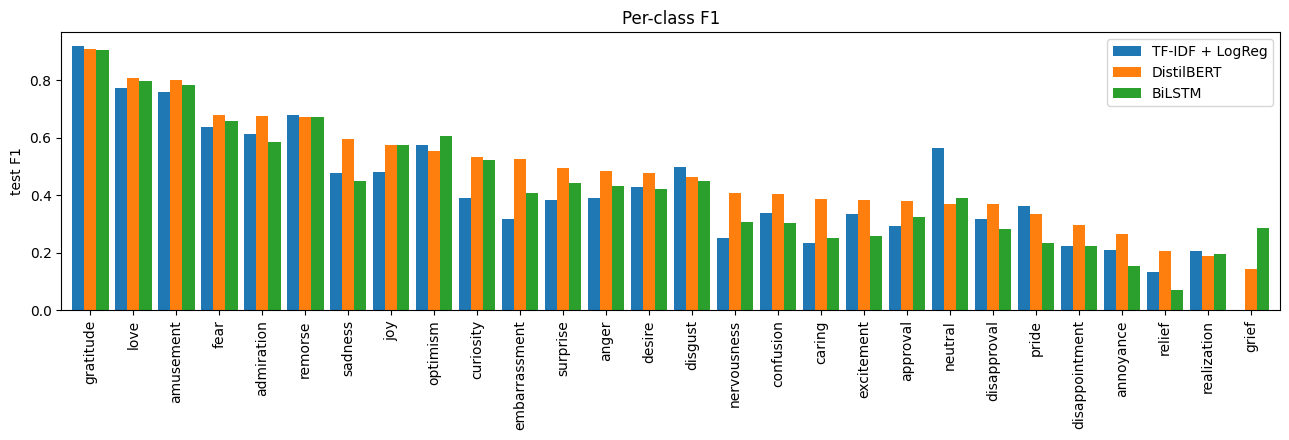

,TF-IDF + LogReg,DistilBERT,BiLSTM,support
gratitude,0.920,0.909,0.904,260
love,0.772,0.808,0.797,160
amusement,0.759,0.800,0.783,186
fear,0.636,0.681,0.657,65
admiration,0.612,0.675,0.586,348
remorse,0.680,0.673,0.672,44
sadness,0.478,0.597,0.450,102
joy,0.482,0.576,0.576,93
optimism,0.574,0.553,0.605,107
curiosity,0.392,0.533,0.521,176


In [12]:
# per-class F1 for all three models
f1s = pd.DataFrame({k: f1_score(y_test, v["preds"], average=None, labels=range(NUM)) for k, v in results.items()},
                   index=names)
f1s["support"] = np.bincount(y_test, minlength=NUM)
f1s = f1s.sort_values("DistilBERT", ascending=False)
f1s.drop(columns="support").plot.bar(figsize=(13, 4.5), width=0.85)
plt.ylabel("test F1"); plt.title("Per-class F1"); plt.tight_layout()
plt.savefig("figures/per_class_f1.png", dpi=150); plt.show()
f1s.round(3)

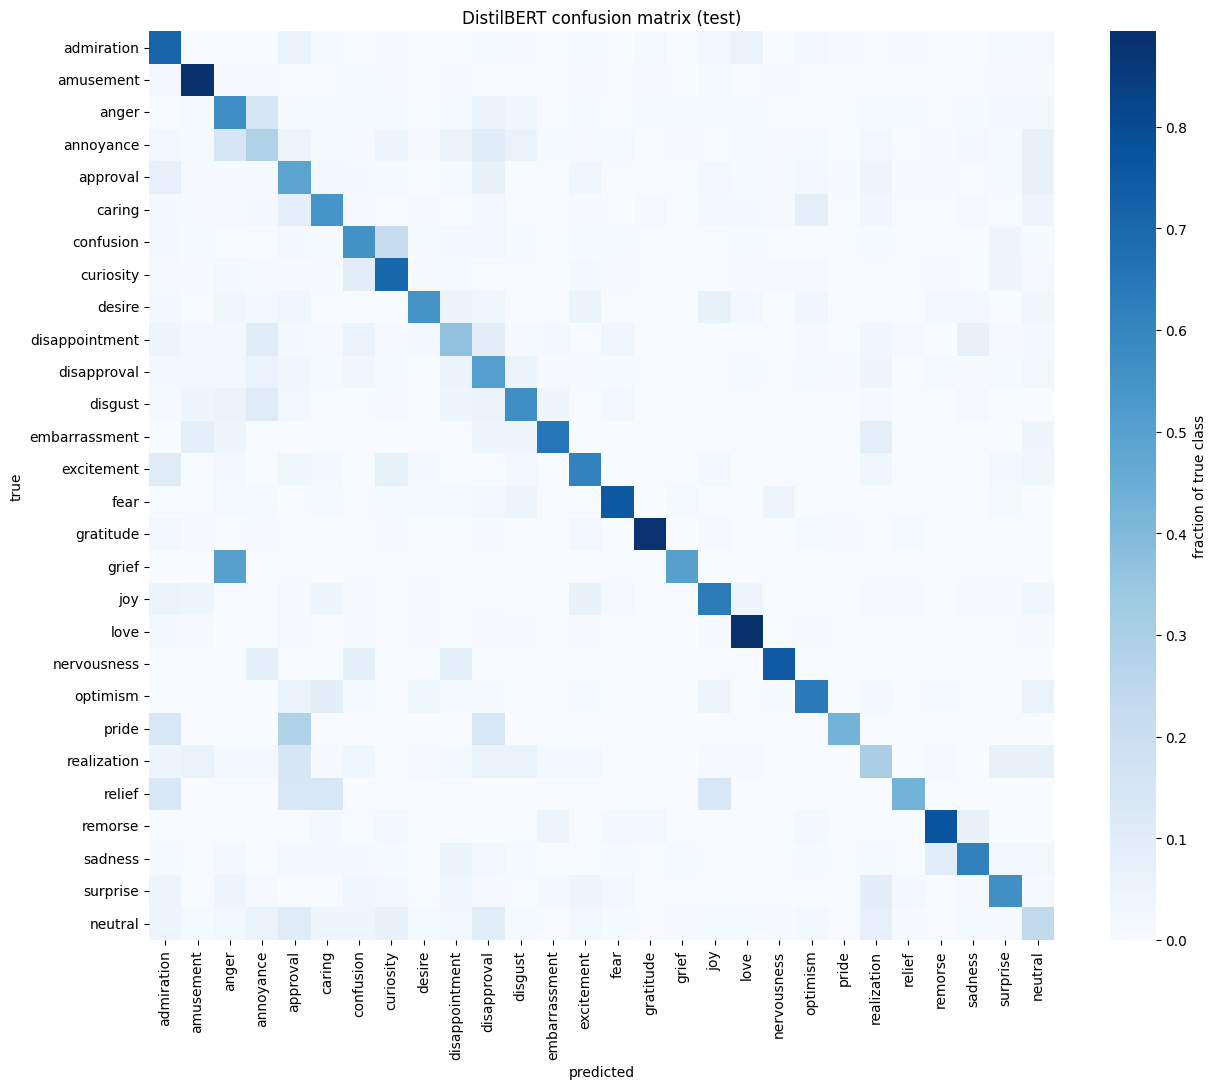

,true,predicted as,fraction
0,grief,anger,0.500
1,pride,approval,0.286
2,confusion,curiosity,0.216
3,realization,approval,0.146
4,anger,annoyance,0.145
5,annoyance,anger,0.144
6,pride,admiration,0.143
7,pride,disapproval,0.143
8,relief,admiration,0.143
9,relief,approval,0.143


In [13]:
# Confusion matrix for DistilBERT (row-normalised)
cm = confusion_matrix(y_test, results["DistilBERT"]["preds"], labels=range(NUM), normalize="true")
plt.figure(figsize=(13, 11))
sns.heatmap(cm, xticklabels=names, yticklabels=names, cmap="Blues", cbar_kws={"label": "fraction of true class"})
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("DistilBERT confusion matrix (test)")
plt.tight_layout(); plt.savefig("figures/confusion_distilbert.png", dpi=150); plt.show()

# most-confused pairs
pairs = [(names[i], names[j], cm[i, j]) for i in range(NUM) for j in range(NUM) if i != j]
pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:12], columns=["true", "predicted as", "fraction"]).round(3)

In [14]:
# Confidently wrong predictions
probs = torch.softmax(bert_logits, 1).numpy()
pred = probs.argmax(1); conf = probs.max(1)
wrong = np.where(pred != y_test)[0]
top = wrong[np.argsort(-conf[wrong])][:15]
pd.set_option("display.max_colwidth", 120)
pd.DataFrame({"text": test_df.text.values[top],
              "true": [names[i] for i in y_test[top]],
              "pred": [names[i] for i in pred[top]],
              "conf": conf[top].round(2)})

,text,true,pred,conf
0,"Thanks for further justifying my support for Tulsi, Daily Gross.",neutral,gratitude,0.99
1,Yeah thank you you ungrateful bast.....,anger,gratitude,0.99
2,Thank you! [NAME] seems to realize how toxic this fanbase can be also.. Now lets hope you all keep your composure wh...,neutral,gratitude,0.99
3,Your comments have been removed. This is a community for support. Repeat violation will result in a ban. Thank you f...,neutral,gratitude,0.99
4,[NAME] looks veeeery nervous,neutral,nervousness,0.99
5,Former [NAME]? I've been scared already by [NAME] who were former d-line,curiosity,fear,0.99
6,I wish that too.,optimism,desire,0.99
7,Have you ever consider knocking three times and that hide and seek/stalker vibe is terrifying. It's the most disturb...,annoyance,fear,0.99
8,Sadly enough I was thinking the same.,remorse,sadness,0.99
9,"Yep California, I would've been surprised if they cleared him.",approval,surprise,0.99


In [15]:
# What does the linear model rely on? Top TF-IDF features per class
feat = np.array(vec.get_feature_names_out())
for c in ["gratitude", "amusement", "fear", "grief", "disgust", "confusion", "annoyance", "anger"]:
    i = names.index(c)
    print(f"{c:>12}: ", ", ".join(feat[np.argsort(-lr.coef_[i])[:8]]))

   gratitude:  thanks, thank, thank you, welcome, glad, thanks for, congrats, appreciate
   amusement:  lol, haha, funny, lmao, hilarious, fun, hahaha, laughed
        fear:  afraid, scared, scary, terrible, terrifying, horrible, dangerous, fear
       grief:  died, rip, dead, death, your loss, bro, deaths, very sorry
     disgust:  disgusting, awful, worst, weird, ugly, nasty, worse, gross
   confusion:  confused, not sure, why, or, confusing, don know, idk, confusion
   annoyance:  annoying, stupid, annoyed, shit, idiots, fucking, pissed, fuck
       anger:  fuck, hate, fucking, angry, stupid, asshole, bitch, stop


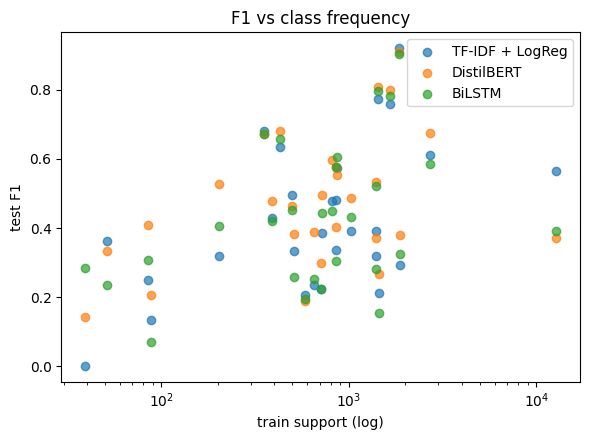

In [16]:
# Effect of class imbalance: F1 vs training support (does the transformer help rare classes more?)
tr_support = np.bincount(train_df.y, minlength=NUM)
d = pd.DataFrame({k: f1_score(y_test, v["preds"], average=None, labels=range(NUM)) for k, v in results.items()}, index=names)
plt.figure(figsize=(6, 4.5))
for k in d: plt.scatter(tr_support, d[k], label=k, alpha=.7)
plt.xscale("log"); plt.xlabel("train support (log)"); plt.ylabel("test F1"); plt.legend()
plt.title("F1 vs class frequency"); plt.tight_layout(); plt.savefig("figures/f1_vs_support.png", dpi=150); plt.show()